# GANTZ: Controlled Financial Augmentation
Complete, self-contained Colab source, with separate cells. Developed 5 November 2026.

**Start with a GPU runtime and the development pilot.** Smoke/pilot scores are not publication results. The full experiment is resumable and can require many Colab sessions. This is a modified TCN/WGAN-GP inspired by Quant GAN/RSQGAN, not an exact reproduction.

**Core question:** does temporal ordering explain the utility of generated return paths after controlling augmentation amount, mean/variance and optimization budget?

The accompanying publication assessment explains the scientific limitations. Do not interpret an ordinary nonsignificant difference as equivalence. Freeze the hypothesis contrasts, training budget and equivalence margin before research tests.

**Conditions:** A0 real only; A1 conditional GAN; A2 unconditional GAN; A3 stationary bootstrap; A4 Gaussian jitter; A5 shuffled real paths; A6 duplicated real paths; A7 shuffled versions of the exact A2 generated paths.

Cells defining the model contain the full code; no external project download is needed.

## Cell 1 — Dependencies

In [3]:
# Keep Colab's own PyTorch/CUDA installation.
%pip install -q "yfinance==1.8.0" "numpy>=1.26,<3" "pandas>=2.2,<3" "scipy>=1.11,<2" "matplotlib>=3.8,<4"
import torch
print("PyTorch:", torch.__version__, "CUDA:", torch.cuda.is_available())
if not torch.cuda.is_available():
    print("CPU detected. Choose Runtime > Change runtime type > GPU for training.")


PyTorch: 2.11.0+cu130 CUDA: True


## Cell 2 — Persistent checkpoint location

In [4]:
from pathlib import Path
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_ROOT = '/content/drive/MyDrive/gantz'
else:
    WORK_ROOT = '/content/gantz_runs'  # Lost if this Colab runtime is deleted.
Path(WORK_ROOT).mkdir(parents=True, exist_ok=True)
print(WORK_ROOT)


Mounted at /content/drive
/content/drive/MyDrive/gantz


## Cell 3 — Imports and configuration

In [5]:
from dataclasses import dataclass, asdict, replace
from pathlib import Path
import copy, hashlib, json, math, os, platform, random, subprocess, sys, time
import importlib.metadata as metadata
import numpy as np
import pandas as pd
from scipy import stats
from scipy.spatial.distance import cdist
import torch
from torch import nn
from torch.nn import functional as F

IMPLEMENTATION_ID = 'gantz-v1.0-689dc77a15437ae7'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

@dataclass(frozen=True)
class Config:
    mode: str = 'pilot'
    ticker: str = 'SPY'
    start: str = '1993-01-01'
    end: str = '2025-01-01'  # exclusive: freezes study to 2024
    years: tuple = (1999,)  # development year, outside the 2000-2024 research tests
    seeds: tuple = (11,)
    train_years: int = 10  # rolling, with shorter history for early folds
    context: int = 128
    horizon: int = 5
    gan_channels: int = 32
    latent: int = 8
    embed: int = 4
    dilations: tuple = (1, 2, 4, 8, 16, 32)  # receptive field = 127
    gan_steps: int = 150
    critic_steps: int = 3
    gp_lambda: float = 10.0
    lr_g: float = 1e-4
    lr_d: float = 4e-4
    batch: int = 64
    forecast_steps: int = 250
    forecast_hidden: int = 32
    forecast_layers: int = 2
    lr_forecast: float = 1e-3
    eval_every: int = 50
    checkpoint_every: int = 100
    ratio: float = 1.0
    jitter: float = 0.20
    matching: str = 'mean_std'  # or 'none' for sensitivity
    block_length: int = 20  # fixed training bootstrap length; test 10/40 separately
    infer_block: int = 20
    bootstrap_reps: int = 1000
    equivalence_margin: float = 0.02  # absolute QLIKE units; MUST justify before testing
    conditions: tuple = ('A0','A1','A2','A3','A4','A5','A6','A7')
    min_regime_windows: int = 20
    root: str = '/content/drive/MyDrive/gantz'
    csv_path: str = ''  # optional Date,Close,VIX; Close must be adjusted

    @property
    def length(self): return self.context + self.horizon

    def validate(self):
        assert self.mode in ('smoke','pilot','research')
        assert self.matching in ('mean_std','none')
        assert self.context >= 22 and self.horizon >= 1
        assert 1 + 2 * sum(self.dilations) <= self.length
        assert self.ratio > 0 and self.block_length >= 1
        assert self.infer_block >= self.horizon
        assert self.gan_steps > 0 and self.forecast_steps > 0
        assert self.eval_every > 0 and self.checkpoint_every > 0
        assert len(set(self.years)) == len(self.years)
        assert len(set(self.seeds)) == len(self.seeds)
        assert set(self.conditions) <= set(('A0','A1','A2','A3','A4','A5','A6','A7'))
        assert 'A7' not in self.conditions or ('A2' in self.conditions and self.conditions.index('A2') < self.conditions.index('A7'))
        assert 'A0' in self.conditions
        assert len(self.years) and len(self.seeds)


def research_config(root='/content/drive/MyDrive/gantz', **kwargs):
    c = Config(mode='research', root=root, years=tuple(range(2000,2025)),
               seeds=(11,22,33,44,55), gan_steps=3000, forecast_steps=1500,
               bootstrap_reps=5000)
    return replace(c, **kwargs)


def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def digest(data): return hashlib.sha256(data).hexdigest()


def atomic_json(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, default=str))
    os.replace(tmp, path)


def atomic_torch(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix('.tmp'); torch.save(obj, tmp); os.replace(tmp, path)


def cpu_state(model):
    return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}


def runtime_info():
    versions = {}
    for name in ('torch','numpy','pandas','scipy','yfinance','matplotlib'):
        try: versions[name] = metadata.version(name)
        except metadata.PackageNotFoundError: versions[name] = None
    return dict(python=sys.version, platform=platform.platform(), versions=versions,
                device=str(DEVICE), cuda=torch.version.cuda,
                gpu=torch.cuda.get_device_name() if torch.cuda.is_available() else None)


## Cell 4 — Data ingestion and strict temporal splits

In [6]:
def prepare_frame(raw):
    """Forecast after close t; regime uses VIX from previous available trading day."""
    raw = raw.copy()
    if 'Date' in raw.columns: raw = raw.set_index('Date')
    raw.index = pd.DatetimeIndex(pd.to_datetime(raw.index)).tz_localize(None)
    raw = raw.sort_index()
    if raw.index.has_duplicates: raise ValueError('Duplicate dates in source data.')
    raw = raw[['Close','VIX']].apply(pd.to_numeric, errors='raise')
    if raw.isna().any().any():
        raise ValueError('Missing Close/VIX rows: resolve data gaps; do not interpolate prices.')
    if not np.isfinite(raw.to_numpy()).all() or (raw <= 0).any().any():
        raise ValueError('Prices and VIX must be finite and positive.')
    if len(raw) < 200: raise ValueError('Insufficient history.')
    raw['r'] = np.log(raw.Close).diff()
    raw['vix_lag'] = raw.VIX.shift(1)
    raw = raw.iloc[1:].copy()
    raw['regime'] = np.digitize(raw.vix_lag, [15.,25.]).astype(int)
    # Fixed thresholds, NOT estimated quantiles; 2 means high volatility, not every crisis.
    return raw


def load_data(cfg):
    cache = Path(cfg.root)/'data'; cache.mkdir(parents=True, exist_ok=True)
    key = digest(f'{cfg.ticker}|{cfg.start}|{cfg.end}|adjusted-v1'.encode())[:12]
    path = Path(cfg.csv_path) if cfg.csv_path else cache/f'prices_{key}.csv'
    if path.exists():
        raw = pd.read_csv(path)
    else:
        import yfinance as yf
        def fetch(symbol):
            last = None
            for attempt in range(3):
                try:
                    d = yf.download(symbol, start=cfg.start, end=cfg.end,
                                    auto_adjust=True, actions=False, progress=False,
                                    threads=False, multi_level_index=False, timeout=30)
                    if d is None or d.empty: raise RuntimeError(f'Empty download: {symbol}')
                    s = d['Close']
                    if isinstance(s, pd.DataFrame): s = s.iloc[:,0]
                    s.index = pd.DatetimeIndex(s.index).tz_localize(None)
                    return s
                except Exception as exc:
                    last = exc
                    if attempt < 2: time.sleep(2 * (attempt+1))
            raise RuntimeError('Download failed. Supply a Date,Close,VIX CSV via csv_path.') from last
        price, vix = fetch(cfg.ticker), fetch('^VIX')
        # Preserve the asset calendar; missing VIX is an error, not a silent join/drop.
        raw = pd.DataFrame({'Close':price, 'VIX':vix.reindex(price.index)})
        raw.index.name = 'Date'
        prepare_frame(raw)  # validate before freezing cache
        raw.to_csv(path)
        atomic_json(dict(source='Yahoo Finance via yfinance', ticker=cfg.ticker,
                         adjusted=True, end_exclusive=cfg.end,
                         fetched_utc=pd.Timestamp.now(tz='UTC').isoformat()),
                    path.with_suffix('.metadata.json'))
    frame = prepare_frame(raw)
    frame = frame.loc[(frame.index >= cfg.start) & (frame.index < cfg.end)]
    return frame, digest(path.read_bytes())


def all_windows(frame, cfg):
    r = frame.r.to_numpy(dtype=np.float64)
    paths = np.lib.stride_tricks.sliding_window_view(r, cfg.length).copy()
    origin = np.arange(len(paths)) + cfg.context - 1
    finish = origin + cfg.horizon
    return dict(paths=paths, origin=origin, finish=finish,
                dates=frame.index[origin], target_dates=frame.index[finish],
                labels=frame.regime.to_numpy()[origin])


def make_fold(frame, cfg, year):
    w = all_windows(frame,cfg)
    test_start, test_end = pd.Timestamp(year,1,1), pd.Timestamp(year+1,1,1)
    val_start = pd.Timestamp(year-1,1,1)
    train_start = max(pd.Timestamp(cfg.start), pd.Timestamp(year-1-cfg.train_years,1,1))
    # Train paths, including targets, end strictly before validation begins.
    path_start = frame.index[w['origin'] - cfg.context + 1]
    tr = (path_start >= train_start) & (w['target_dates'] < val_start)
    va = (w['dates'] >= val_start) & (w['target_dates'] < test_start)
    te = (w['dates'] >= test_start) & (w['target_dates'] < test_end)
    source = frame.loc[(frame.index >= train_start) & (frame.index < val_start),'r'].to_numpy()
    if tr.sum() < 500 or va.sum() < 100 or te.sum() < 100:
        raise ValueError(f'Insufficient complete train/validation/test windows for {year}.')
    if frame.index.max() < test_end-pd.Timedelta(days=10):
        raise ValueError(f'Test year {year} is not complete in the supplied data.')
    mean, std = float(source.mean()), float(source.std())
    if std < 1e-10: raise ValueError('Degenerate return series.')
    out = dict(year=year, mean=mean, std=std, source=source)
    for name, mask in [('train',tr),('val',va),('test',te)]:
        out[name] = {k:np.asarray(v)[mask] for k,v in w.items()}
    assert out['train']['target_dates'].max() < out['val']['dates'].min()
    assert out['val']['target_dates'].max() < out['test']['dates'].min()
    counts = np.bincount(out['train']['labels'],minlength=3)
    if 'A1' in cfg.conditions and counts.min() < cfg.min_regime_windows:
        raise ValueError(f'{year}: insufficient regime support {counts}; revise protocol before running.')
    out['regime_counts'] = counts.tolist()
    return out


def supervised(paths, cfg, mean, std):
    """Generate labels from each path's OWN future; no label copying after augmentation."""
    x = ((paths[:,:cfg.context] - mean) / std).astype(np.float32)[...,None]
    variance = np.maximum(252. * np.mean(paths[:,cfg.context:]**2,axis=1),1e-12)
    return x, np.log(variance).astype(np.float32), variance


## Cell 5 — Causal temporal convolutional generator and critic

In [7]:
class CausalConv(nn.Module):
    def __init__(self, cin, cout, dilation):
        super().__init__(); self.pad = dilation
        self.conv = nn.Conv1d(cin,cout,kernel_size=2,dilation=dilation)
    def forward(self,x): return self.conv(F.pad(x,(self.pad,0)))


class ResidualTCN(nn.Module):
    def __init__(self, cin, channels, dilations):
        super().__init__()
        self.input = nn.Conv1d(cin,channels,1)
        self.blocks = nn.ModuleList([
            nn.Sequential(CausalConv(channels,channels,d),nn.LeakyReLU(0.2),
                          CausalConv(channels,channels,d),nn.LeakyReLU(0.2))
            for d in dilations])
        self.receptive = 1 + 2 * sum(dilations)
    def forward(self,x):
        x = self.input(x)
        for block in self.blocks: x = (x + block(x)) / math.sqrt(2)
        return x


class Generator(nn.Module):
    def __init__(self,cfg,conditional):
        super().__init__(); self.cfg = cfg; self.conditional = conditional
        # Identical parameter count for A1/A2; A2 always receives null label 0.
        self.embedding = nn.Embedding(3,cfg.embed)
        self.tcn = ResidualTCN(cfg.latent+cfg.embed,cfg.gan_channels,cfg.dilations)
        self.head = nn.Conv1d(cfg.gan_channels,1,1)
        self.burn = self.tcn.receptive-1
    def forward(self,z,labels):
        labels = labels if self.conditional else torch.zeros_like(labels)
        e = self.embedding(labels)[:,:,None].expand(-1,-1,z.shape[-1])
        return self.head(self.tcn(torch.cat([z,e],dim=1)))[:,:,self.burn:]
    def sample(self,labels):
        z = torch.randn(len(labels),self.cfg.latent,self.cfg.length+self.burn,device=labels.device)
        return self(z,labels)


class Critic(nn.Module):
    def __init__(self,cfg,conditional):
        super().__init__(); self.conditional = conditional
        self.embedding = nn.Embedding(3,cfg.embed)
        self.tcn = ResidualTCN(1+cfg.embed,cfg.gan_channels,cfg.dilations)
        self.head = nn.Conv1d(cfg.gan_channels,1,1)
    def forward(self,x,labels):
        labels = labels if self.conditional else torch.zeros_like(labels)
        e = self.embedding(labels)[:,:,None].expand(-1,-1,x.shape[-1])
        h = self.tcn(torch.cat([x,e],dim=1))
        # Discard padding-affected positions instead of scoring artificial zeros.
        return self.head(h)[:,:,self.tcn.receptive-1:].mean((1,2))


def gradient_penalty(critic,real,fake,labels):
    a = torch.rand(len(real),1,1,device=real.device)
    mix = (a*real + (1-a)*fake).requires_grad_(True)
    score = critic(mix,labels)
    g = torch.autograd.grad(score.sum(),mix,create_graph=True)[0]
    return ((g.flatten(1).norm(2,dim=1)-1)**2).mean()


## Cell 6 — WGAN-GP training, checkpoints, and sampling

In [8]:
def train_gan(fold,cfg,seed,conditional,directory):
    directory = Path(directory); directory.mkdir(parents=True,exist_ok=True)
    ck = directory/'checkpoint.pt'
    seed_all(seed)
    g, d = Generator(cfg,conditional).to(DEVICE), Critic(cfg,conditional).to(DEVICE)
    og = torch.optim.Adam(g.parameters(),lr=cfg.lr_g,betas=(0.,0.9))
    od = torch.optim.Adam(d.parameters(),lr=cfg.lr_d,betas=(0.,0.9))
    real = torch.tensor((fold['train']['paths']-fold['mean'])/fold['std'],
                        dtype=torch.float32,device=DEVICE)[:,None,:]
    labels = torch.tensor(fold['train']['labels'],dtype=torch.long,device=DEVICE)
    begin, log = 0, []
    if ck.exists():
        s = torch.load(ck,map_location=DEVICE,weights_only=True)
        g.load_state_dict(s['g']); d.load_state_dict(s['d'])
        og.load_state_dict(s['og']); od.load_state_dict(s['od'])
        begin, log = s['step'], s['log']
    elapsed = time.monotonic()
    for step in range(begin,cfg.gan_steps):
        # Step-specific RNG makes restart independent of draws made before interruption.
        seed_all(seed*1000003 + step)
        for p in d.parameters(): p.requires_grad_(True)
        for _ in range(cfg.critic_steps):
            ids = torch.randint(len(real),(cfg.batch,),device=DEVICE)
            xr, c = real[ids], labels[ids]
            with torch.no_grad(): fake = g.sample(c)
            od.zero_grad(set_to_none=True)
            gp = gradient_penalty(d,xr,fake,c)
            ld = d(fake,c).mean()-d(xr,c).mean()+cfg.gp_lambda*gp
            if not torch.isfinite(ld): raise FloatingPointError('Nonfinite critic loss; run retained as failed.')
            ld.backward(); od.step()
        for p in d.parameters(): p.requires_grad_(False)
        ids = torch.randint(len(real),(cfg.batch,),device=DEVICE)
        og.zero_grad(set_to_none=True)
        lg = -d(g.sample(labels[ids]),labels[ids]).mean()
        if not torch.isfinite(lg): raise FloatingPointError('Nonfinite generator loss; run retained as failed.')
        lg.backward(); og.step()
        if (step+1)%cfg.eval_every == 0 or step+1 == cfg.gan_steps:
            row = dict(step=step+1,critic=float(ld.detach()),generator=float(lg.detach()),gp=float(gp.detach()))
            log.append(row)
            print(f"GAN {'A1' if conditional else 'A2'} {step+1}/{cfg.gan_steps}: {row}",flush=True)
        if (step+1)%cfg.checkpoint_every == 0 or step+1 == cfg.gan_steps:
            atomic_torch(dict(g=g.state_dict(),d=d.state_dict(),og=og.state_dict(),
                              od=od.state_dict(),step=step+1,log=log),ck)
            pd.DataFrame(log).to_csv(directory/'training.csv',index=False)
    atomic_json(dict(last_session_seconds=time.monotonic()-elapsed,
                     parameters_g=sum(p.numel() for p in g.parameters()),
                     parameters_d=sum(p.numel() for p in d.parameters()),
                     conditional=conditional),directory/'model_info.json')
    return g.eval()


@torch.no_grad()
def generate(g,fold,cfg,n,seed):
    seed_all(seed)
    rng = np.random.default_rng(seed)
    # Same empirical label proportions as the training windows, no stress oversampling.
    probs = np.bincount(fold['train']['labels'],minlength=3).astype(float)
    probs /= probs.sum()
    counts = np.floor(probs*n).astype(int)
    for j in np.argsort(-(probs*n-counts))[:n-counts.sum()]: counts[j] += 1
    labels = np.repeat(np.arange(3),counts); rng.shuffle(labels)
    result = []
    for i in range(0,n,cfg.batch):
        c = torch.tensor(labels[i:i+cfg.batch],dtype=torch.long,device=DEVICE)
        result.append(g.sample(c)[:,0].cpu().numpy())
    paths = np.concatenate(result).astype(float)*fold['std']+fold['mean']
    if not np.isfinite(paths).all(): raise FloatingPointError('Nonfinite generated paths.')
    return paths, labels


## Cell 7 — Augmentation controls and pooled marginal matching

In [9]:
def stationary_indices(n_source,n_paths,length,block,rng):
    idx = np.empty((n_paths,length),dtype=np.int64)
    idx[:,0] = rng.integers(n_source,size=n_paths)
    for t in range(1,length):
        restart = rng.random(n_paths) < 1./block
        idx[:,t] = np.where(restart,rng.integers(n_source,size=n_paths),(idx[:,t-1]+1)%n_source)
    return idx


def match_marginals(paths,reference,mode):
    """Match ONLY pooled mean/std; never match away the temporal mechanism under test."""
    if mode == 'none': return paths.copy()
    scale = paths.std()
    if not np.isfinite(scale) or scale < 1e-10:
        raise FloatingPointError('Collapsed pool cannot be variance matched; report the failure.')
    return (paths-paths.mean())/scale*reference.std()+reference.mean()


def make_augmentations(fold,cfg,seed,directory):
    real = fold['train']['paths']; n = max(1,round(cfg.ratio*len(real)))
    pools, raw, labels = {}, {}, {}
    for method in cfg.conditions:
        if method == 'A0': continue
        rng = np.random.default_rng(seed+1000)
        if method in ('A1','A2'):
            g = train_gan(fold,cfg,seed,method=='A1',Path(directory)/method)
            p, lab = generate(g,fold,cfg,n,seed+2000)
            labels[method] = lab
            del g
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        elif method == 'A3':
            ids = stationary_indices(len(fold['source']),n,cfg.length,cfg.block_length,rng)
            p = fold['source'][ids]
        elif method == 'A4':
            p = real[rng.integers(len(real),size=n)].copy()
            p += rng.normal(0,cfg.jitter*fold['std'],size=p.shape)
        elif method == 'A5':
            # Independently reorder each sampled joint context+future path.
            # Exactly preserves that path's multiset; destroys ordering, not all dependence.
            p = real[rng.integers(len(real),size=n)].copy()
            for row in p: rng.shuffle(row)
        elif method == 'A6':
            # Duplication/resampling sanity check; introduces no new joint examples.
            p = real[rng.integers(len(real),size=n)].copy()
        elif method == 'A7':
            # Paired temporal ablation of A2: exactly the SAME generated return values.
            p = raw['A2'].copy()
            for row in p: rng.shuffle(row)
        raw[method] = p
        # Do not alter A6: it must remain exact resampling, even if variance differs slightly.
        pools[method] = p.copy() if method=='A6' else match_marginals(p,real,cfg.matching)
    return pools,raw,labels


## Cell 8 — Fidelity, dependence, diversity, and memorization diagnostics

In [10]:
def corr(a,b):
    a,b = np.asarray(a).ravel(),np.asarray(b).ravel()
    if a.std()<1e-15 or b.std()<1e-15: return float('nan')
    return float(np.corrcoef(a,b)[0,1])


def path_acf(paths,lag,power=1):
    p = np.abs(paths)**power if power!=1 else paths
    return corr(p[:,:-lag],p[:,lag:])  # never join independent paths


def fidelity(paths,reference,train_paths,seed=0):
    a,b = paths.ravel(),reference.ravel()
    row = dict(mean=float(a.mean()),variance=float(a.var()),
               variance_ratio=float(a.var()/b.var()),skew=float(stats.skew(a)),
               excess_kurtosis=float(stats.kurtosis(a)),
               q01=float(np.quantile(a,.01)),q99=float(np.quantile(a,.99)),
               wasserstein=float(stats.wasserstein_distance(a,b)),
               ks_stat=float(stats.ks_2samp(a,b).statistic))  # no invalid IID p-value
    for lag in (1,5,10,20):
        if lag>=paths.shape[1]: continue
        for power,label in ((1,'return'),(2,'squared')):
            value = path_acf(paths,lag,power)
            row[f'acf_{label}_{lag}'] = value
            row[f'acf_{label}_error_{lag}'] = abs(value-path_acf(reference,lag,power))
        row[f'acf_abs_{lag}'] = corr(np.abs(paths[:,:-lag]),np.abs(paths[:,lag:]))
        row[f'leverage_{lag}'] = corr(paths[:,:-lag],paths[:,lag:]**2)
    rng = np.random.default_rng(seed)
    # Bounded memory; report nearest-neighbor metric as diagnostic, not a privacy proof.
    query = paths[rng.choice(len(paths),min(256,len(paths)),replace=False)]
    train = train_paths[rng.choice(len(train_paths),min(1024,len(train_paths)),replace=False)]
    scale = max(train_paths.std(),1e-12)
    distances = cdist(query/scale,train/scale)/math.sqrt(paths.shape[1])
    row['nearest_train_rmse_median'] = float(np.median(distances.min(1)))
    row['near_exact_fraction_sampled'] = float(np.mean(distances.min(1)<1e-6))
    if len(query)>1:
        row['pairwise_rmse_mean'] = float(cdist(query[:len(query)//2]/scale,
                                             query[len(query)//2:]/scale).mean()/math.sqrt(paths.shape[1]))
    return row


def diagnostics_table(pools,raw,labels,fold,cfg,seed):
    rows=[]
    refs={'train':fold['train']['paths'], 'validation':fold['val']['paths']}
    for method,p in pools.items():
        for stage,paths in [('raw',raw[method]),('matched',p)]:
            for refname,ref in refs.items():
                row=fidelity(paths,ref,fold['train']['paths'],seed)
                row.update(method=method,stage=stage,reference=refname,regime='all')
                rows.append(row)
        if method=='A1':
            for regime in range(3):
                psub=p[labels[method]==regime]
                ref=fold['train']['paths'][fold['train']['labels']==regime]
                if len(psub) and len(ref):
                    row=fidelity(psub,ref,fold['train']['paths'],seed)
                    row.update(method=method,stage='matched',reference='train',regime=str(regime))
                    rows.append(row)
    return pd.DataFrame(rows)


## Cell 9 — Fixed downstream model, equal optimization budgets, and simple benchmarks

In [11]:
class Forecaster(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.lstm = nn.LSTM(1,cfg.forecast_hidden,cfg.forecast_layers,batch_first=True)
        self.head = nn.Linear(cfg.forecast_hidden,1)
    def forward(self,x): return self.head(self.lstm(x)[0][:,-1]).squeeze(-1)


@torch.no_grad()
def predict(model,x,batch=256):
    model.eval()
    return np.concatenate([model(torch.tensor(x[i:i+batch],device=DEVICE)).cpu().numpy()
                           for i in range(0,len(x),batch)])


def train_forecaster(train_paths,fold,cfg,seed,directory):
    directory=Path(directory); directory.mkdir(parents=True,exist_ok=True)
    ck=directory/'forecaster.pt'
    seed_all(seed)
    model=Forecaster(cfg).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=cfg.lr_forecast)
    x,y,_=supervised(train_paths,cfg,fold['mean'],fold['std'])
    xv,yv,_=supervised(fold['val']['paths'],cfg,fold['mean'],fold['std'])
    # Identical output scaling from real training targets for every condition.
    _,yr,_=supervised(fold['train']['paths'],cfg,fold['mean'],fold['std'])
    ym,ys=float(yr.mean()),max(float(yr.std()),1e-6)
    xx=torch.tensor(x,device=DEVICE); yy=torch.tensor((y-ym)/ys,device=DEVICE)
    start,best,history=0,float('inf'),[]; best_state=None
    if ck.exists():
        s=torch.load(ck,map_location=DEVICE,weights_only=True)
        model.load_state_dict(s['model']); opt.load_state_dict(s['opt'])
        start,best,history,best_state=s['step'],s['best'],s['history'],s['best_state']
    for step in range(start,cfg.forecast_steps):
        seed_all(seed*1000003+step)
        model.train(); ids=torch.randint(len(xx),(cfg.batch,),device=DEVICE)
        opt.zero_grad(set_to_none=True)
        loss=F.mse_loss(model(xx[ids]),yy[ids])
        if not torch.isfinite(loss): raise FloatingPointError('Nonfinite downstream loss.')
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),5.); opt.step()
        if (step+1)%cfg.eval_every==0 or step+1==cfg.forecast_steps:
            pred=predict(model,xv)*ys+ym
            vl=float(np.mean((pred-yv)**2))
            history.append(dict(step=step+1,train_loss=float(loss.detach()),val_log_variance_mse=vl))
            if np.isfinite(vl) and vl<best: best=vl; best_state=cpu_state(model)
        if (step+1)%cfg.checkpoint_every==0 or step+1==cfg.forecast_steps:
            atomic_torch(dict(model=model.state_dict(),opt=opt.state_dict(),step=step+1,
                              best=best,best_state=best_state,history=history),ck)
            pd.DataFrame(history).to_csv(directory/'forecast_training.csv',index=False)
    if best_state is None: raise FloatingPointError('No finite validation checkpoint.')
    model.load_state_dict(best_state)
    xt,yt,actual=supervised(fold['test']['paths'],cfg,fold['mean'],fold['std'])
    loghat=predict(model,xt)*ys+ym
    # Explicit numerical safeguard; clipping counts are part of the output.
    clipped=(loghat < -20)|(loghat > 5)
    predvar=np.exp(np.clip(loghat,-20,5))
    return prediction_frame(fold,actual,predvar,clipped),model,dict(y_mean=ym,y_std=ys)


def prediction_frame(fold,actual,predvar,clipped=None):
    ratio=actual/np.maximum(predvar,1e-12)
    return pd.DataFrame(dict(date=pd.to_datetime(fold['test']['dates']),
                             target_end=pd.to_datetime(fold['test']['target_dates']),
                             regime=fold['test']['labels'],actual_variance=actual,
                             predicted_variance=predvar,
                             qlike=ratio-np.log(np.maximum(ratio,1e-300))-1,
                             log_vol_sq_error=(.5*np.log(actual)-.5*np.log(predvar))**2,
                             vol_abs_error=np.abs(np.sqrt(actual)-np.sqrt(predvar)),
                             clipped=False if clipped is None else clipped))


def benchmark_predictions(fold,cfg):
    tr,te=fold['train']['paths'],fold['test']['paths']
    _,_,actual=supervised(te,cfg,fold['mean'],fold['std'])
    def features(p):
        return np.column_stack([np.ones(len(p))]+[
            np.log(np.maximum(252*np.mean(p[:,cfg.context-k:cfg.context]**2,axis=1),1e-12))
            for k in (1,5,22)])
    _,target,_=supervised(tr,cfg,fold['mean'],fold['std'])
    # HAR-like daily-squared-return proxy regression, not classical intraday HAR-RV.
    coef=np.linalg.lstsq(features(tr),target,rcond=None)[0]
    harlog=features(te)@coef
    historical=252*np.mean(te[:,cfg.context-22:cfg.context]**2,axis=1)
    return {'B_HIST22':prediction_frame(fold,actual,np.maximum(historical,1e-12)),
            'B_HAR_proxy':prediction_frame(fold,actual,np.exp(np.clip(harlog,-20,5)),
                                           (harlog < -20)|(harlog > 5))}


## Cell 10 — Paired temporal inference, equivalence, and descriptive summaries

In [12]:
def holm(p):
    p=np.asarray(p,float); order=np.argsort(p); out=np.empty(len(p))
    out[order]=np.minimum(1,np.maximum.accumulate((len(p)-np.arange(len(p)))*p[order]))
    return out


def circular_indices(n, block, rng):
    starts = rng.integers(n, size=math.ceil(n/block))
    return ((starts[:,None]+np.arange(block))%n).ravel()[:n]


def compare_methods(pred,cfg):
    """Seed-paired, within-year block bootstrap. Conditional on evaluated historical years.
    Seeds are resampled as paired runs, never counted as extra independent trading days.
    """
    pairs=[('A1','A2'),('A1','A3'),('A2','A3'),('A1','A4'),('A2','A4'),
           ('A1','A5'),('A2','A5'),('A3','A4'),('A2','A7')]
    pairs += [(m,'A0') for m in cfg.conditions if m!='A0']
    rows=[]
    for left,right in pairs:
        sub=pred[pred.method.isin([left,right])]
        if set(sub.method)!=set([left,right]): continue
        # Cross-fold grouping retains actual chronological gaps at year boundaries.
        wide=sub.pivot(index=['year','date','seed'],columns='method',values='qlike')
        if wide[[left,right]].isna().any().any(): raise ValueError('Unpaired predictions.')
        diff=(wide[left]-wide[right]).rename('d').reset_index()
        arrays=[]
        for year,part in diff.groupby('year',sort=True):
            a=part.pivot(index='date',columns='seed',values='d').sort_index()
            if a.isna().any().any() or tuple(a.columns)!=tuple(sorted(cfg.seeds)):
                raise ValueError('Incomplete seed/fold matrix; do not silently exclude failed runs.')
            arrays.append(a.to_numpy())
        n=sum(len(a) for a in arrays)
        observed=sum(a.mean(1).sum() for a in arrays)/n
        rng=np.random.default_rng(20261105)
        draws=np.empty(cfg.bootstrap_reps)
        for b in range(cfg.bootstrap_reps):
            seed_ids=rng.integers(len(cfg.seeds),size=len(cfg.seeds))
            total=0.
            for a in arrays:
                ids=circular_indices(len(a),cfg.infer_block,rng)
                total += a[ids][:,seed_ids].mean(1).sum()
            draws[b]=total/n
        centered=draws-observed
        p=(1+np.sum(np.abs(centered)>=abs(observed)))/(len(draws)+1)
        lo,hi=np.quantile(draws,[.025,.975]); elo,ehi=np.quantile(draws,[.05,.95])
        # HAC normal approximation: DM-style supplementary test, no year-boundary covariance.
        lrv_sum=0.
        for a in arrays:
            d=a.mean(1); z=d-d.mean(); N=len(z)
            lag=min(N-1,max(cfg.horizon-1,int(4*(N/100)**(2/9))))
            lrv=float(z@z/N)
            for k in range(1,lag+1): lrv+=2*(1-k/(lag+1))*float(z[k:]@z[:-k]/N)
            lrv_sum+=N*max(lrv,0.)
        se=math.sqrt(lrv_sum)/n
        z=observed/se if se>0 else (0. if observed==0 else np.sign(observed)*np.inf)
        rows.append(dict(left=left,right=right,delta_qlike=observed,ci95_low=lo,ci95_high=hi,
                         bootstrap_p=p,hac_p=float(2*stats.norm.sf(abs(z))),
                         ci90_low=elo,ci90_high=ehi,equivalence_margin=cfg.equivalence_margin,
                         equivalent_unadjusted=bool(elo>-cfg.equivalence_margin and ehi<cfg.equivalence_margin),
                         n_dates=n,n_seeds=len(cfg.seeds),n_years=len(arrays)))
    table=pd.DataFrame(rows)
    if len(table):
        table['bootstrap_p_holm']=holm(table.bootstrap_p)
        table['hac_p_holm']=holm(table.hac_p)
        table['run_mode']=cfg.mode
        table['inference_scope']='conditional on these historical years; equivalence unadjusted'
    return table


def summarize(pred):
    records=[]
    for keys,g in pred.groupby(['year','seed','method']):
        for regime in ['all',0,1,2]:
            q=g if regime=='all' else g[g.regime==regime]
            if not len(q): continue
            records.append(dict(year=keys[0],seed=keys[1],method=keys[2],regime=str(regime),
                n=len(q),qlike=q.qlike.mean(),rmse_log_vol=np.sqrt(q.log_vol_sq_error.mean()),
                mae_vol=q.vol_abs_error.mean(),clip_count=int(q.clipped.sum())))
    return pd.DataFrame(records)


## Cell 11 — Experiment orchestration and audit trail

In [13]:
def run_experiment(cfg,frame=None,data_hash=None,max_jobs=None):
    cfg.validate()
    if frame is None: frame,data_hash=load_data(cfg)
    if data_hash is None: data_hash=digest(frame.to_csv().encode())
    signature=dict(config={k:v for k,v in asdict(cfg).items() if k not in ('root','csv_path')},
                   data_sha256=data_hash,implementation=IMPLEMENTATION_ID)
    run_id=digest(json.dumps(signature,sort_keys=True).encode())[:16]
    root=Path(cfg.root)/f'{cfg.mode}_{cfg.ticker}_{run_id}'; root.mkdir(parents=True,exist_ok=True)
    manifest=root/'manifest.json'
    if manifest.exists():
        saved=json.loads(manifest.read_text())
        if saved['runtime']['versions'] != runtime_info()['versions']:
            raise RuntimeError('Package versions changed. Restore the recorded environment or use a new root for a fresh run.')
    if not manifest.exists():
        atomic_json(dict(**signature,runtime=runtime_info(),
                         created_utc=pd.Timestamp.now(tz='UTC').isoformat()),manifest)
        freeze=subprocess.run([sys.executable,'-m','pip','freeze'],capture_output=True,text=True)
        (root/'environment_freeze.txt').write_text(freeze.stdout)
        frame.to_csv(root/'analysis_data.csv')
    print(f'Run: {root}\nDevice: {DEVICE}; mode={cfg.mode}. Pilot/smoke results are NOT paper evidence.',flush=True)
    jobs=0
    for year in cfg.years:
        fold=make_fold(frame,cfg,year)
        for seed in cfg.seeds:
            dest=root/f'year_{year}'/f'seed_{seed}'; dest.mkdir(parents=True,exist_ok=True)
            if (dest/'DONE.json').exists(): continue
            if max_jobs is not None and jobs>=max_jobs:
                print('Session job limit reached; rerun to continue.'); return root
            print(f'Start year={year}, seed={seed}; regime support={fold["regime_counts"]}',flush=True)
            started=time.monotonic()
            try:
                atomic_json(dict(year=year,seed=seed,mean=fold['mean'],std=fold['std'],
                                 regime_counts=fold['regime_counts'],
                                 split_counts={k:len(fold[k]['paths']) for k in ('train','val','test')},
                                 split_dates={k:[str(fold[k]['dates'].min()),str(fold[k]['target_dates'].max())]
                                              for k in ('train','val','test')}),dest/'fold.json')
                pools,raw,labels=make_augmentations(fold,cfg,seed,dest)
                np.savez_compressed(dest/'augmentation_pools.npz',**pools)
                diagnostics_table(pools,raw,labels,fold,cfg,seed).to_csv(dest/'diagnostics.csv',index=False)
                predictions=[]
                for method in cfg.conditions:
                    real=fold['train']['paths']
                    train=real if method=='A0' else np.concatenate([real,pools[method]])
                    pf,model,yscale=train_forecaster(train,fold,cfg,seed,dest/method)
                    pf['method']=method; predictions.append(pf)
                    atomic_torch(dict(state=cpu_state(model),config=asdict(cfg),
                                      input_mean=fold['mean'],input_std=fold['std'],**yscale),
                                 dest/method/'inference.pt')
                    del model
                    print(f'{year}/{seed}/{method}: QLIKE={pf.qlike.mean():.4f}',flush=True)
                for method,pf in benchmark_predictions(fold,cfg).items():
                    pf['method']=method; predictions.append(pf)
                pred=pd.concat(predictions,ignore_index=True); pred['year']=year; pred['seed']=seed
                pred.to_csv(dest/'predictions.csv',index=False)
                atomic_json(dict(seconds_this_session=time.monotonic()-started),dest/'DONE.json')
                if (dest/'FAILED.json').exists(): (dest/'FAILED.json').unlink()
                jobs+=1
            except Exception as exc:
                atomic_json(dict(error=repr(exc),year=year,seed=seed),dest/'FAILED.json')
                raise  # never hide failed GAN seeds or continue with missing conditions
    expected=len(cfg.years)*len(cfg.seeds)
    completed=list(root.glob('year_*/seed_*/DONE.json'))
    if len(completed)!=expected: raise RuntimeError('Incomplete experiment; final inference withheld.')
    pred=pd.concat([pd.read_csv(p.parent/'predictions.csv',parse_dates=['date','target_end'])
                    for p in completed],ignore_index=True)
    pred.to_csv(root/'all_predictions.csv',index=False)
    summary=summarize(pred); summary.to_csv(root/'metrics_by_year_seed_regime.csv',index=False)
    comparison=compare_methods(pred,cfg); comparison.to_csv(root/'paired_comparisons.csv',index=False)
    diag=pd.concat([pd.read_csv(p.parent/'diagnostics.csv').assign(
                    year=int(p.parent.parent.name.split('_')[1]),seed=int(p.parent.name.split('_')[1]))
                    for p in completed],ignore_index=True)
    diag.to_csv(root/'all_diagnostics.csv',index=False)
    return root


## Cell 12 — Figures and inference from a saved forecaster

In [14]:
def plot_results(root):
    import matplotlib.pyplot as plt
    root=Path(root); m=pd.read_csv(root/'metrics_by_year_seed_regime.csv')
    allreg=m[m.regime.astype(str)=='all']
    # First average seeds inside each year; show yearly variation, not fake seed replication.
    yearly=allreg.groupby(['year','method']).qlike.mean().unstack()
    fig,ax=plt.subplots(figsize=(11,5))
    yearly.mean().sort_values().plot.bar(ax=ax,color='#246b8e')
    ax.set(ylabel='Mean yearly QLIKE (lower is better)',title='Equal-weight annual performance')
    ax.tick_params(axis='x',rotation=35); fig.tight_layout()
    fig.savefig(root/'mean_qlike.png',dpi=180); plt.show()
    fig,ax=plt.subplots(figsize=(11,5))
    for method in yearly.columns:
        ax.plot(np.arange(len(yearly)),yearly[method],marker='o',label=method)
    ax.set_xticks(np.arange(len(yearly)),yearly.index.astype(str),rotation=45)
    ax.legend(fontsize=8,ncol=2)
    ax.set(ylabel='QLIKE',title='Out-of-sample performance by year')
    fig.tight_layout(); fig.savefig(root/'yearly_qlike.png',dpi=180); plt.show()
    fig,ax=plt.subplots(figsize=(11,5))
    regime=m[m.regime.astype(str)!='all'].groupby(['regime','method']).qlike.mean().unstack()
    regime.plot.bar(ax=ax); ax.set(ylabel='QLIKE',xlabel='Lagged VIX regime',title='Regime-stratified descriptive performance')
    ax.tick_params(axis='x',rotation=0); fig.tight_layout()
    fig.savefig(root/'regime_qlike.png',dpi=180); plt.show()
    diag=pd.read_csv(root/'all_diagnostics.csv')
    diag=diag[(diag.stage=='matched') & (diag.reference=='train') & (diag.regime.astype(str)=='all')].copy()
    cols=[c for c in diag if c.startswith('acf_squared_error_')]
    diag['acf_squared_error_mean']=diag[cols].mean(axis=1)
    joined=allreg.merge(diag,on=['year','seed','method'],suffixes=('','_diagnostic'))
    base=allreg[allreg.method=='A0'][['year','seed','qlike']].rename(columns={'qlike':'baseline_qlike'})
    joined=joined.merge(base,on=['year','seed'])
    joined['qlike_gain_vs_A0']=joined.baseline_qlike-joined.qlike
    joined.to_csv(root/'fidelity_vs_utility.csv',index=False)
    fig,ax=plt.subplots(figsize=(9,5))
    for method,q in joined.groupby('method'):
        ax.scatter(q.acf_squared_error_mean,q.qlike_gain_vs_A0,label=method,alpha=.65)
    ax.axhline(0,color='gray',lw=1); ax.legend(fontsize=8)
    ax.set(xlabel='Mean squared-return ACF error (lags 1, 5, 10, 20)',
           ylabel='QLIKE improvement over A0',title='Fidelity versus utility: descriptive, not causal')
    fig.tight_layout(); fig.savefig(root/'fidelity_vs_utility.png',dpi=180); plt.show()
    return yearly


@torch.no_grad()
def forecast_saved(checkpoint,recent_returns):
    s=torch.load(checkpoint,map_location=DEVICE,weights_only=True)
    cfg=Config(**s['config']); model=Forecaster(cfg).to(DEVICE)
    model.load_state_dict(s['state']); model.eval()
    r=np.asarray(recent_returns,dtype=float)[-cfg.context:]
    if len(r)!=cfg.context or not np.isfinite(r).all(): raise ValueError('Need context-length finite log returns.')
    x=torch.tensor(((r-s['input_mean'])/s['input_std']).astype(np.float32),device=DEVICE)[None,:,None]
    logvar=float(model(x).item()*s['y_std']+s['y_mean'])
    variance=float(np.exp(np.clip(logvar,-20,5)))
    return dict(annualized_variance=variance,annualized_volatility=math.sqrt(variance),
                horizon_trading_days=cfg.horizon,clipped=not(-20<=logvar<=5))


## Cell 13 — Software verification (simulated data; not paper evidence)

GAN A1 2/2: {'step': 2, 'critic': 9.588801383972168, 'generator': -0.24997957050800323, 'gp': 0.9632120132446289}
GAN A1 4/4: {'step': 4, 'critic': 9.602992057800293, 'generator': -0.24491766095161438, 'gp': 0.9636019468307495}
GAN A1 2/4: {'step': 2, 'critic': 9.588801383972168, 'generator': -0.24997957050800323, 'gp': 0.9632120132446289}
GAN A1 4/4: {'step': 4, 'critic': 9.602992057800293, 'generator': -0.24491766095161438, 'gp': 0.9636019468307495}
Run: /tmp/gantz_checks_p6nqc1jf/smoke_SPY_e993f07cd4adb832
Device: cuda; mode=smoke. Pilot/smoke results are NOT paper evidence.
Start year=2020, seed=3; regime support=[597, 600, 600]
GAN A1 2/2: {'step': 2, 'critic': 9.588801383972168, 'generator': -0.24997957050800323, 'gp': 0.9632120132446289}
GAN A2 2/2: {'step': 2, 'critic': 9.574755668640137, 'generator': -0.2510262131690979, 'gp': 0.9619253873825073}
2020/3/A0: QLIKE=0.7637
2020/3/A1: QLIKE=0.7637
2020/3/A2: QLIKE=0.7638
2020/3/A3: QLIKE=0.7637
2020/3/A4: QLIKE=0.7637
2020/3/A5: Q

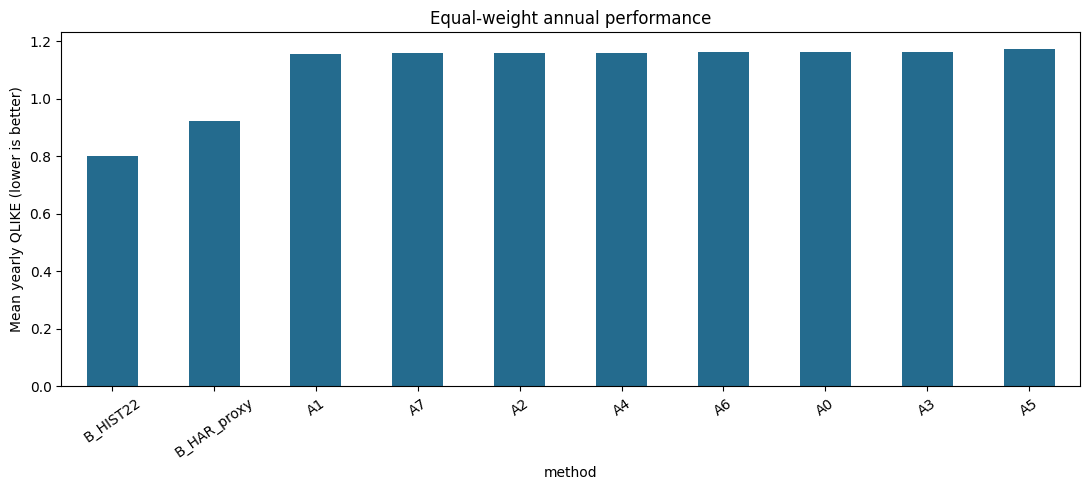

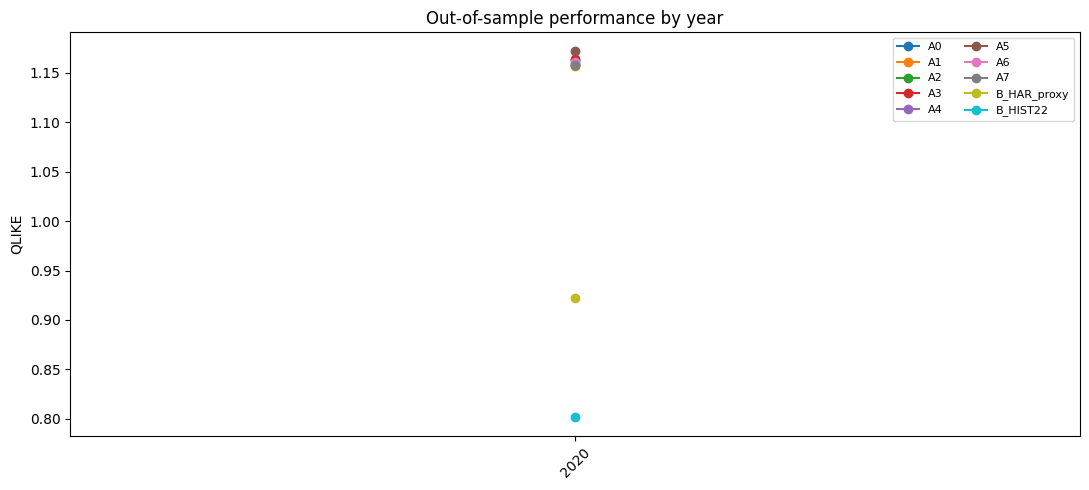

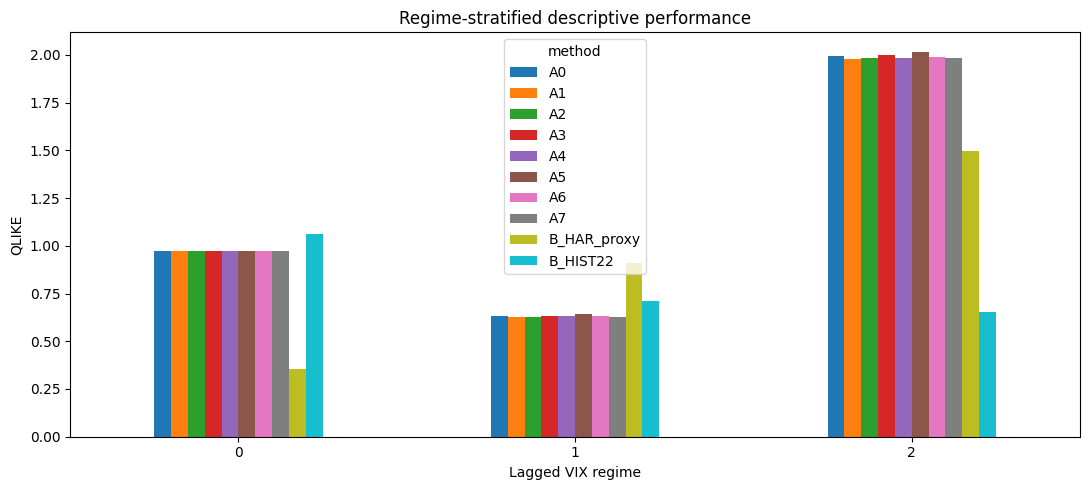

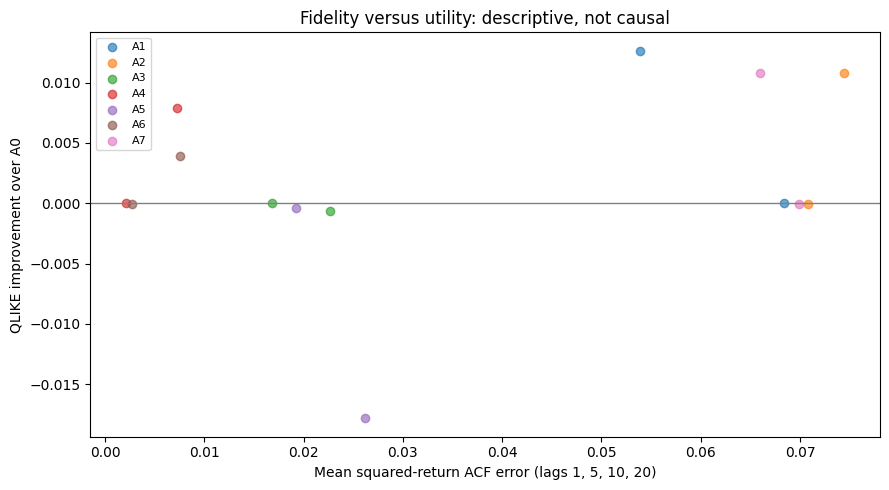

PASS: leakage, target alignment, causal TCN, gradients, matching, paired ablation,
checkpoint resume, complete experiment, paired inference, saved inference, figures.


In [15]:
"""Meaningful invariant and end-to-end checks; simulated data are NOT research results."""
from pathlib import Path
from dataclasses import replace
import tempfile
import numpy as np
import pandas as pd
import torch


def synthetic_fixture():
    rng=np.random.default_rng(4321)
    dates=pd.bdate_range('2012-01-02','2021-12-31')
    n=len(dates); state=(np.arange(n)//40)%3
    r=np.zeros(n); sigma=np.array([.005,.012,.025])[state]
    for i in range(1,n): r[i]=.10*r[i-1]+sigma[i]*rng.standard_t(6)/np.sqrt(1.5)
    raw=pd.DataFrame(dict(Date=dates,Close=100*np.exp(np.cumsum(r)),VIX=np.array([12.,20.,32.])[state]))
    return prepare_frame(raw)


def run_checks(directory=None):
    torch.set_num_threads(2)
    root=Path(directory or tempfile.mkdtemp(prefix='gantz_checks_'))
    c=Config(mode='smoke',root=str(root),start='2012-01-01',end='2022-01-01',
             years=(2020,),seeds=(3,7),context=24,dilations=(1,2,4),
             gan_channels=4,latent=2,embed=2,batch=8,forecast_hidden=4,forecast_layers=1,
             gan_steps=2,critic_steps=1,forecast_steps=4,eval_every=2,checkpoint_every=2,
             bootstrap_reps=99,min_regime_windows=5)
    frame=synthetic_fixture(); f=make_fold(frame,c,2020)
    # Changing future data cannot change training paths, scaling, or origin regime.
    future=frame.copy(); mask=future.index>=pd.Timestamp('2019-01-01')
    future.loc[mask,'r'] *= 3
    f2=make_fold(future,c,2020)
    np.testing.assert_array_equal(f['train']['paths'],f2['train']['paths'])
    assert f['mean']==f2['mean'] and f['std']==f2['std']
    # Future labels align exactly with the next H returns, not the context.
    p=np.arange(c.length,dtype=float)[None,:]/1000
    x,y,v=supervised(p,c,0,1)
    np.testing.assert_allclose(v,252*np.mean(p[:,c.context:]**2,axis=1))
    assert x.shape==(1,c.context,1)
    # Causal convolution: future noise changes cannot alter earlier outputs.
    seed_all(1); tcn=ResidualTCN(2,4,(1,2,4)).eval()
    z=torch.randn(2,2,60); z2=z.clone(); z2[:,:,40:] += 10
    with torch.no_grad(): torch.testing.assert_close(tcn(z)[:,:,:40],tcn(z2)[:,:,:40])
    # Generator shape and gradient penalty second-order backward.
    g,d=Generator(c,True),Critic(c,True)
    labels=torch.tensor([0,1,2]); fake=g.sample(labels)
    assert fake.shape==(3,1,c.length)
    gp=gradient_penalty(d,torch.randn_like(fake),fake.detach(),labels)
    gp.backward(); assert np.isfinite(float(gp.detach()))
    # Mean/std matching and order-destruction preserve pooled values as specified.
    rng=np.random.default_rng(2); original=rng.normal(size=(100,c.length))
    matched=match_marginals(original,f['train']['paths'],'mean_std')
    np.testing.assert_allclose(matched.mean(),f['train']['paths'].mean(),atol=1e-12)
    np.testing.assert_allclose(matched.std(),f['train']['paths'].std(),atol=1e-12)
    for row in original: rng.shuffle(row)
    ids=stationary_indices(100,20,30,10,rng)
    assert ids.min()>=0 and ids.max()<100
    # QLIKE is zero for perfect predictions.
    perfect=prediction_frame(f,np.ones(len(f['test']['paths'])),np.ones(len(f['test']['paths'])))
    np.testing.assert_allclose(perfect.qlike,0)
    # Exact same-environment GAN checkpoint resume vs uninterrupted training.
    full=replace(c,gan_steps=4)
    train_gan(f,c,3,True,root/'resume')
    resumed=train_gan(f,full,3,True,root/'resume')
    uninterrupted=train_gan(f,full,3,True,root/'uninterrupted')
    for key,val in resumed.state_dict().items():
        torch.testing.assert_close(val,uninterrupted.state_dict()[key],rtol=0,atol=0)
    result=run_experiment(c,frame=frame)
    pred=pd.read_csv(result/'all_predictions.csv')
    assert len(pred.method.unique())==len(c.conditions)+2
    assert np.isfinite(pred.qlike).all() and not pred.clipped.any()
    # Paired A7 permutation preserves each A2 path's exact multiset after matching.
    for pth in result.glob('year_*/seed_*/augmentation_pools.npz'):
        data=np.load(pth)
        np.testing.assert_allclose(np.sort(data['A2'],axis=1),np.sort(data['A7'],axis=1),atol=1e-12)
    before=(result/'all_predictions.csv').read_bytes()
    assert run_experiment(c,frame=frame)==result
    assert (result/'all_predictions.csv').read_bytes()==before
    checkpoint=result/'year_2020'/'seed_3'/'A0'/'inference.pt'
    out=forecast_saved(checkpoint,frame.r.to_numpy())
    assert np.isfinite(out['annualized_volatility'])
    comparisons=pd.read_csv(result/'paired_comparisons.csv')
    assert comparisons.bootstrap_p.between(0,1).all()
    assert (comparisons.bootstrap_p_holm >= comparisons.bootstrap_p-1e-12).all()
    plot_results(result)
    print('PASS: leakage, target alignment, causal TCN, gradients, matching, paired ablation,')
    print('checkpoint resume, complete experiment, paired inference, saved inference, figures.')
    return result



RUN_CHECKS = True
if RUN_CHECKS:
    validation_directory = run_checks()


## Cell 14 — Select development or research configuration

In [16]:
# The pilot uses 1999, outside research test years 2000-2024.
# Research: 25 years x 5 seeds = 125 jobs, 250 GAN fits, 1000 LSTM fits.
# Freeze these choices BEFORE looking at research outcomes.
#MODE = 'pilot'  # change to 'research' only after development checks
#CSV_PATH = ''  # optional existing CSV with Date, Close (adjusted), VIX
#cfg = (research_config(root=WORK_ROOT, csv_path=CSV_PATH)
       #if MODE == 'research' else Config(root=WORK_ROOT, csv_path=CSV_PATH))
# Optional overrides, selected using development data only:
# cfg = replace(cfg, gan_steps=5000, forecast_steps=2000)
# cfg = replace(cfg, ratio=0.5)  # declared sensitivity, creates a separate run
# cfg = replace(cfg, matching='none')
# cfg = replace(cfg, block_length=10)
# cfg = replace(cfg, ticker='QQQ', start='1999-01-01', years=tuple(range(2005,2025)))
# QQQ example is a separate univariate replication, not joint multi-asset generation.
#cfg.validate()
#torch.set_num_threads(2)
#print(json.dumps(asdict(cfg), indent=2))
#print(runtime_info())                              #first cell 14


#first edit
MODE = "pilot"
CSV_PATH = ""

cfg = replace(
    Config(root=WORK_ROOT, csv_path=CSV_PATH),
    mode="pilot",
    years=(1999,),
    seeds=(11, 22, 33),
    gan_steps=1500,
    forecast_steps=1000,
    eval_every=100,
    checkpoint_every=100,
)

cfg.validate()
print(json.dumps(asdict(cfg), indent=2))



#addition after 1st edit
# Continue development on 1999.
# Change only the GAN training budget.
assert cfg.mode == "pilot"
assert tuple(cfg.years) == (1999,)
assert tuple(cfg.seeds) == (11, 22, 33)

cfg = replace(cfg, gan_steps=3000)
cfg.validate()

print("GAN updates:", cfg.gan_steps)
print("Forecaster updates:", cfg.forecast_steps)  # remains 1000
print("Seeds:", cfg.seeds)


{
  "mode": "pilot",
  "ticker": "SPY",
  "start": "1993-01-01",
  "end": "2025-01-01",
  "years": [
    1999
  ],
  "seeds": [
    11,
    22,
    33
  ],
  "train_years": 10,
  "context": 128,
  "horizon": 5,
  "gan_channels": 32,
  "latent": 8,
  "embed": 4,
  "dilations": [
    1,
    2,
    4,
    8,
    16,
    32
  ],
  "gan_steps": 1500,
  "critic_steps": 3,
  "gp_lambda": 10.0,
  "lr_g": 0.0001,
  "lr_d": 0.0004,
  "batch": 64,
  "forecast_steps": 1000,
  "forecast_hidden": 32,
  "forecast_layers": 2,
  "lr_forecast": 0.001,
  "eval_every": 100,
  "checkpoint_every": 100,
  "ratio": 1.0,
  "jitter": 0.2,
  "matching": "mean_std",
  "block_length": 20,
  "infer_block": 20,
  "bootstrap_reps": 1000,
  "equivalence_margin": 0.02,
  "conditions": [
    "A0",
    "A1",
    "A2",
    "A3",
    "A4",
    "A5",
    "A6",
    "A7"
  ],
  "min_regime_windows": 20,
  "root": "/content/drive/MyDrive/gantz",
  "csv_path": ""
}
GAN updates: 3000
Forecaster updates: 1000
Seeds: (11, 22, 33)


## Cell 15 — Download/cache data and audit all temporal splits

In [17]:
frame, data_hash = load_data(cfg)
print('Observed period:', frame.index.min(), 'to', frame.index.max())
print('Rows:', len(frame), 'SHA256:', data_hash)
# Audit all splits before spending time training.
audit = []
for year in cfg.years:
    f = make_fold(frame, cfg, year)
    audit.append(dict(year=year, train=len(f['train']['paths']),
                      validation=len(f['val']['paths']), test=len(f['test']['paths']),
                      regime_counts=f['regime_counts']))
display(pd.DataFrame(audit))


Observed period: 1993-02-01 00:00:00 to 2024-12-31 00:00:00
Rows: 8037 SHA256: 18c4f69aa8167e3b35a5a5031af48fe7c544e2a437d3b4e8cb800cba7bc7e16d


,year,train,validation,test,regime_counts
0,1999,1112,247,247,"[584, 490, 38]"


## Cell 16 — Train and resume experiments

In [18]:
# Each job is one test year and one seed, including all conditions.
# Rerun this cell unchanged to resume the next incomplete job.
# An interrupted job restores GAN/LSTM checkpoints; completed jobs are skipped.
MAX_JOBS = 1  # Set to None to continue until every configured job completes.
run_dir = run_experiment(cfg, frame=frame, data_hash=data_hash, max_jobs=MAX_JOBS)
print('Run directory:', run_dir)
print('Completed jobs:', len(list(run_dir.glob('year_*/seed_*/DONE.json'))),
      '/', len(cfg.years)*len(cfg.seeds))


Run: /content/drive/MyDrive/gantz/pilot_SPY_a1a680af9f359466
Device: cuda; mode=pilot. Pilot/smoke results are NOT paper evidence.
Start year=1999, seed=33; regime support=[584, 490, 38]
GAN A1 100/3000: {'step': 100, 'critic': -9.375126838684082, 'generator': -0.7979928851127625, 'gp': 0.24541547894477844}
GAN A1 200/3000: {'step': 200, 'critic': -7.73653507232666, 'generator': -3.4905707836151123, 'gp': 0.04778272286057472}
GAN A1 300/3000: {'step': 300, 'critic': -3.428394317626953, 'generator': -5.082117080688477, 'gp': 0.02672624960541725}
GAN A1 400/3000: {'step': 400, 'critic': -2.0866281986236572, 'generator': -3.6475915908813477, 'gp': 0.04041731357574463}
GAN A1 500/3000: {'step': 500, 'critic': -2.072878122329712, 'generator': -3.189790725708008, 'gp': 0.01761304773390293}
GAN A1 600/3000: {'step': 600, 'critic': -2.315739393234253, 'generator': 0.17494016885757446, 'gp': 0.019265050068497658}
GAN A1 700/3000: {'step': 700, 'critic': -2.292797803878784, 'generator': 0.390848

## Cell 17 — Results and plots (requires all configured jobs)

,year,seed,method,regime,n,qlike,rmse_log_vol,mae_vol,clip_count
0,1999,11,A0,all,247,0.238755,0.342924,0.045020,0
1,1999,11,A0,1,151,0.266593,0.364374,0.046294,0
2,1999,11,A0,2,96,0.194969,0.306158,0.043016,0
3,1999,11,A1,all,247,0.258657,0.350647,0.047114,0
4,1999,11,A1,1,151,0.287211,0.371902,0.047659,0
...,...,...,...,...,...,...,...,...,...
85,1999,33,B_HAR_proxy,1,151,0.423211,0.409198,0.053905,0
86,1999,33,B_HAR_proxy,2,96,0.309540,0.339240,0.049902,0
87,1999,33,B_HIST22,all,247,0.213241,0.365538,0.045691,0
88,1999,33,B_HIST22,1,151,0.265530,0.412402,0.051154,0


,left,right,delta_qlike,ci95_low,ci95_high,bootstrap_p,hac_p,ci90_low,ci90_high,equivalence_margin,equivalent_unadjusted,n_dates,n_seeds,n_years,bootstrap_p_holm,hac_p_holm,run_mode,inference_scope
0,A1,A2,0.004147,-0.044814,0.050044,0.850150,0.717423,-0.035445,0.043319,0.02,False,247,3,1,1.0,1.000000,pilot,conditional on these historical years; equival...
1,A1,A3,-0.038953,-0.133580,0.039781,0.361638,0.081385,-0.117929,0.024271,0.02,False,247,3,1,1.0,1.000000,pilot,conditional on these historical years; equival...
2,A2,A3,-0.043100,-0.146254,0.043686,0.381618,0.137928,-0.131217,0.027854,0.02,False,247,3,1,1.0,1.000000,pilot,conditional on these historical years; equival...
3,A1,A4,-0.018165,-0.119681,0.041140,0.645355,0.262692,-0.095174,0.036192,0.02,False,247,3,1,1.0,1.000000,pilot,conditional on these historical years; equival...
4,A2,A4,-0.022312,-0.117703,0.063693,0.565435,0.167548,-0.094022,0.044317,0.02,False,247,3,1,1.0,1.000000,pilot,conditional on these historical years; equival...
5,A1,A5,0.014364,-0.026293,0.066079,0.504496,0.351476,-0.017241,0.053268,0.02,False,247,3,1,1.0,1.000000,pilot,conditional on these historical years; equival...
6,A2,A5,0.010217,-0.038989,0.063348,0.620380,0.613784,-0.030341,0.054107,0.02,False,247,3,1,1.0,1.000000,pilot,conditional on these historical years; equival...
7,A3,A4,0.020788,-0.036460,0.089112,0.505495,0.380378,-0.028737,0.074168,0.02,False,247,3,1,1.0,1.000000,pilot,conditional on these historical years; equival...
8,A2,A7,-0.040963,-0.129560,0.057236,0.341658,0.183673,-0.112498,0.038070,0.02,False,247,3,1,1.0,1.000000,pilot,conditional on these historical years; equival...
9,A1,A0,-0.029586,-0.139482,0.042624,0.540460,0.090982,-0.122496,0.034444,0.02,False,247,3,1,1.0,1.000000,pilot,conditional on these historical years; equival...


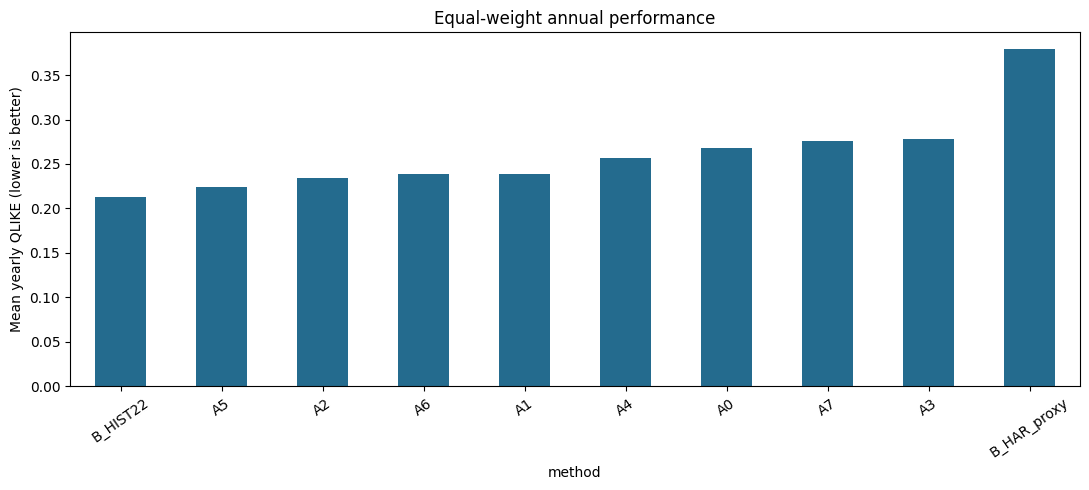

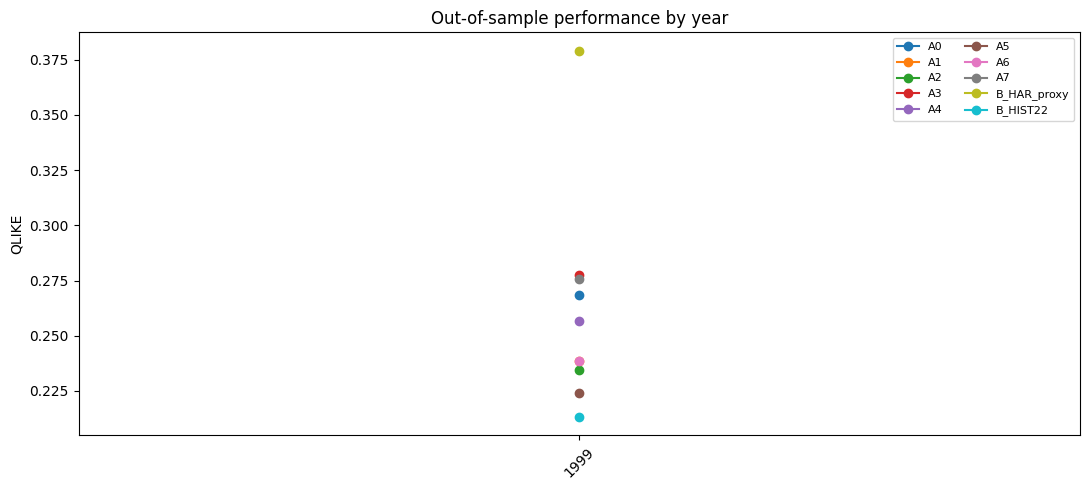

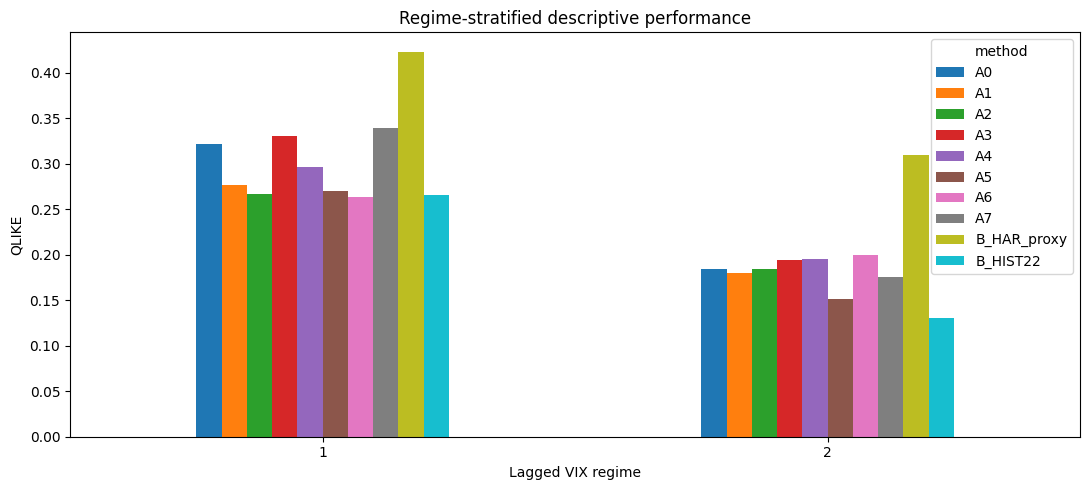

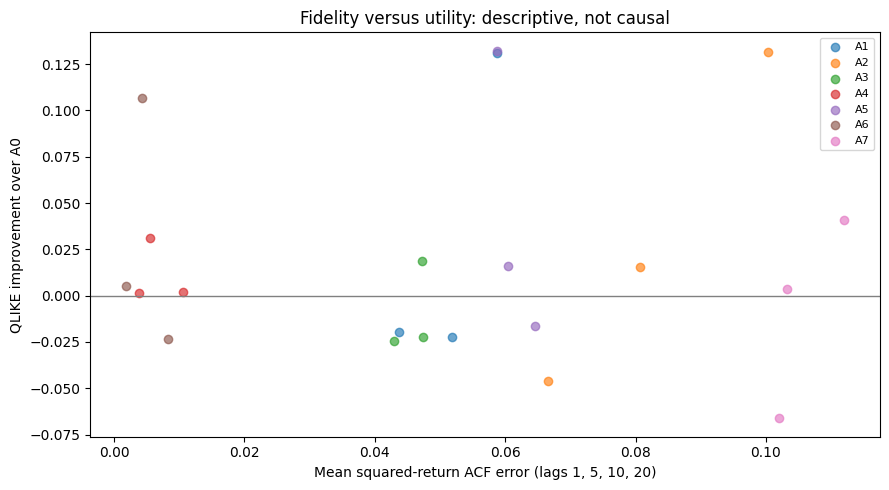

Negative delta_qlike favors the LEFT method.
CIs are individual; superiority p-values have Holm correction.
Equivalence flags are unadjusted, require a justified prespecified margin,
and are not inferred from an ordinary nonsignificant p-value.
Pilot/smoke outputs are DEVELOPMENT ONLY. No hypotheses are automatically accepted.


In [19]:
if (run_dir/'all_predictions.csv').exists():
    metrics = pd.read_csv(run_dir/'metrics_by_year_seed_regime.csv')
    comparisons = pd.read_csv(run_dir/'paired_comparisons.csv')
    display(metrics)
    display(comparisons)
    yearly = plot_results(run_dir)
    print('Negative delta_qlike favors the LEFT method.')
    print('CIs are individual; superiority p-values have Holm correction.')
    print('Equivalence flags are unadjusted, require a justified prespecified margin,')
    print('and are not inferred from an ordinary nonsignificant p-value.')
    print('Pilot/smoke outputs are DEVELOPMENT ONLY. No hypotheses are automatically accepted.')
else:
    print('Experiment incomplete. Rerun the training cell with the same configuration.')


## Cell 18 — Inference-block sensitivity without retraining (optional)

In [20]:
RUN_INFERENCE_SENSITIVITY = False
if RUN_INFERENCE_SENSITIVITY:
    predictions = pd.read_csv(run_dir/'all_predictions.csv', parse_dates=['date','target_end'])
    for block in (10,20,40):
        table = compare_methods(predictions, replace(cfg, infer_block=block))
        table.to_csv(run_dir/f'paired_comparisons_block_{block}.csv', index=False)
        display(table)
# Do not choose the block length with the smallest test p-value.


## Cell 19 — Use a trained model

In [21]:
# Example using A0 from the last configured year and first seed.
checkpoint = run_dir/f'year_{cfg.years[-1]}'/f'seed_{cfg.seeds[0]}'/'A0'/'inference.pt'
if checkpoint.exists():
    result = forecast_saved(checkpoint, frame.r.to_numpy())
    print(result)
    print('Forecast origin:', frame.index[-1], '(the cached dataset end, not today)')
else:
    print('That year/seed is not complete yet.')


{'annualized_variance': 0.04213895404357277, 'annualized_volatility': 0.20527774853493685, 'horizon_trading_days': 5, 'clipped': False}
Forecast origin: 2024-12-31 00:00:00 (the cached dataset end, not today)


## Cell 20 — Download results

In [22]:
# Exclude large checkpoint/pool files by default; they remain in Drive.
import zipfile
EXPORT_ALL_CHECKPOINTS = False
export_path = Path('/content')/(run_dir.name + '_results.zip')
if not Path('/content').exists():
    export_path = Path.cwd()/(run_dir.name + '_results.zip')
with zipfile.ZipFile(export_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for file in run_dir.rglob('*'):
        if file.is_file() and (EXPORT_ALL_CHECKPOINTS or file.suffix not in ('.pt','.npz')):
            archive.write(file, file.relative_to(run_dir))
print(export_path)
from google.colab import files
files.download(str(export_path))


/content/pilot_SPY_a1a680af9f359466_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Protocol and interpretation notes

# GANTZ: Controlled Financial Augmentation Experiments

A complete Colab-first research implementation for **Testing Whether Temporal Structure Explains the Utility of Synthetic Financial Data**. Original Python implementation inspired by Quant GAN, RSQGAN and WGAN-GP. This is **not** an exact reproduction of any of those papers and includes no copied third-party source files.

## Start here

Open `GANTZ_Colab.ipynb` in Google Colab, choose a GPU runtime, and run cells in order. The notebook contains the full source: it does not depend on a private repository or an unavailable download. Alternatively, copy the individual fenced cells from `GANTZ_Copy_Paste_Cells.md` into a blank notebook.

The default is a **development pilot on 1999**, one seed, 150 generator updates and 250 forecasting updates. This checks runtime and basic behavior; these short training budgets cannot establish generator quality. The research preset uses all calendar test years 2000-2024, five paired seeds, 3,000 generator updates and 1,500 forecaster updates. These are starting budgets, not evidence of convergence. Calibrate budgets using development data, then freeze them before inspecting research tests.

The full research preset is substantial: 125 year/seed jobs, 250 GAN fits and 1,000 neural forecaster fits. Do not expect it to finish in a single free Colab session. `MAX_JOBS=1` runs at most one incomplete year/seed job per invocation. Rerun the run cell with the identical configuration to continue. Checkpoints persist in Google Drive when `USE_DRIVE=True`; do not change the configuration midway. Changing the configuration creates a different run directory. A numerical failure stops the experiment and leaves `FAILED.json`; failed seeds are never silently dropped.

## Implemented experiment

- SPY adjusted daily close and lagged VIX, 1993-2024; cached downloads with SHA-256 and a CSV input alternative.
- Return history of 128 trading days; future horizon of five days. Target annualized variance is `252 * mean(next_five_returns**2)`; train the LSTM on log variance. Log-volatility RMSE uses half that log target. This is a daily-return volatility proxy, not intraday realized volatility.
- A rolling training interval of up to 10 years, followed by one validation year and one test year. Early folds have fewer years because SPY begins in 1993. Windows whose future labels cross a split boundary are purged. Historical input context may overlap an earlier split because that information is already known at prediction time.
- VIX from the previous asset trading day defines low `<15`, medium `15 <= VIX <25`, and high `>=25`. These are fixed thresholds, not quantiles, and high VIX is not identical to every crisis. No future segmentation or HMM smoothing is used.
- A causal residual TCN generator and critic, receptive field 127. The generator discards a 126-step warm-up. WGAN-GP is trained in float32 with no BatchNorm, no simultaneous spectral normalization, no latent truncation, and no return clipping. Those are explicit choices, not a claim of exact Quant GAN / RSQGAN reproduction.
- A1 and A2 have identical parameter counts. A2 receives a constant null conditioning label; A1 receives a lagged-VIX label at the forecast origin. A1 sampling follows empirical training-label proportions. Therefore this studies access to conditioning at the observed regime mixture; it does **not** implement deliberate crisis oversampling or a full regime-transition generator.
- Every joint generated path contains context and its own future. Every synthetic label is recomputed from that future after matching. Independent paths are never stitched together to create a forecasting window.
- Equal augmentation ratio and equal optimizer-update budget for all neural forecasters. The same LSTM architecture, initialization seed, validation selection schedule and train-only normalization are used across conditions. All models complete the fixed budget; the checkpoint with lowest validation log-variance MSE is evaluated.

| Condition | Definition | Interpretation |
|---|---|---|
| A0 | Real only | Reference |
| A1 | Lagged-VIX conditional TCN/WGAN-GP | Conditional generation |
| A2 | Null-label TCN/WGAN-GP | Unconditional generation |
| A3 | Stationary circular bootstrap, mean block length 20 | Resampled historical dependence; artificial block joins remain |
| A4 | Additive Gaussian noise, scale 0.2 of train return SD | Perturbation; still retains dependence |
| A5 | Independently shuffle each sampled real joint path | Order-destruction control; preserves each path's multiset |
| A6 | Duplicate/resample complete real joint paths | No-new-information control |
| A7 | Independently shuffle each exact A2 generated path | Paired ablation of GAN ordering, preserving each path's multiset |

A1-A5 and A7 are matched to the real training **window pool's** pooled mean and standard deviation. This removes two marginal differences only. A6 remains exact resampling and is not transformed. A2/A7 have identical marginal values per path. Shuffling also changes input-target relationships and preserves path-level volatility mixtures, so it does not remove every form of dependence. The full framework gives controlled evidence, not unique causal identification of all financial mechanisms.

Two non-neural benchmarks are included: a trailing 22-day variance estimate and a HAR-like regression using 1/5/22-day daily-squared-return proxies. The latter is explicitly **not** the classical intraday HAR-RV model.

## Inference and interpretation

Primary scalar loss is QLIKE: `actual/predicted - log(actual/predicted) - 1`, on **variance**, not volatility. Additional results are log-volatility RMSE and volatility MAE. Report all predeclared contrasts; do not select the best GAN and best control after seeing test outcomes.

`paired_comparisons.csv` uses matched daily losses, resamples paired seed identities, and resamples contiguous circular date blocks separately within each test year. It reports percentile confidence intervals, a centered-bootstrap two-sided p-value, Holm correction across available contrasts, and a supplementary HAC/DM-style asymptotic test. HAC lags are at least horizon minus one. The bootstrap's default block length is 20; repeat inference with 10 and 40, without retraining, as a declared sensitivity analysis.

The pooled comparison table weights forecast dates equally; the mean-year plot explicitly weights years equally. These are different summaries and must be labeled accordingly.

Inference is conditional on the historical years tested. It is not a claim that years, crisis episodes, seeds, or overlapping five-day targets are independent. Each year and regime is also reported descriptively; the code does not compress sparse, noncontiguous high-VIX dates into a fake regular time series for a DM test.

Equivalence is flagged only when the 90% bootstrap interval lies within a predeclared absolute QLIKE margin. The supplied **0.02 is a starting value requiring scientific justification**, not an established standard or a 2% improvement. These equivalence flags are explicitly unadjusted/exploratory across the comparison family. Preregister A2 versus A3 as a single primary equivalence contrast, or apply an appropriate family adjustment before confirmatory claims. `p > .05` alone never supports equivalence. For the diversity explanation, both equivalence and a useful gain over A0 are needed; even then, the result only supports the sufficiency of that control in this setup.

Validation diagnostics are reported regardless of quality: raw/matched moments, tails, Wasserstein and KS statistics, return/absolute/squared-return correlations, leverage correlations, sampled nearest-training-path distance and pairwise diversity. KS p-values are deliberately omitted because paths and observations overlap. Diagnostics are never used to discard finite low-fidelity GAN seeds. Mean-variance matching does not constitute matching effective sample size, tails, temporal dependence or all diversity properties. `fidelity_vs_utility.csv` and its plot are descriptive associations, not causal mediation analysis.

## Outputs

Every run includes a configuration/runtime manifest, frozen package versions, frozen analysis CSV, input hash, per-fold split dates/scales/regime support, generator and downstream checkpoints, raw/matched diagnostic tables, matched augmentation pools, per-date predictions, by-year/seed/regime metrics, paired comparison tables, and figures. Inference checkpoints contain the selected model and training normalization.

`forecast_saved()` returns a five-day annualized variance/volatility estimate from the last context-length daily log returns. The log-variance output is bounded to [-20,5] solely to prevent numerical overflow; clipping is recorded and must be disclosed if it occurs. Training itself uses no such clipping.

Results include internal data snapshots for reproducibility. The distributed code package contains no downloaded market data or pretrained models. Optional multi-asset joint generation, FRED vintage features, online HMMs, TTS-GAN/diffusion backbones, regime-transition fidelity and stress-targeted mixtures are extensions, not unfinished dependencies of the implemented core study.

## Local execution

```bash
pip install -r requirements.txt
python validation.py
python main.py --mode pilot --root ./runs --max-jobs 1
python main.py --mode research --root ./runs --max-jobs 1
```

Use the same Python/CUDA/library versions for a clean reproduction. Colab's installed PyTorch is retained to avoid breaking its CUDA pairing. `environment_freeze.txt` records actual versions; `tested_environment.json` records the development environment. Determinism is requested, but cross-hardware bitwise identity is not promised. Checkpoint restart was tested for exact generator equality on the CPU environment used here.

## Sources

Method references and dependency links are in `REFERENCES.md`; the publication assessment and suggested protocol are in `Publication_Assessment.md`. All supplied experiment source is newly written. External libraries retain their own licenses. When presenting results, cite the original methods and describe the deviations listed above.

## Publication assessment

# Publication assessment and implementation decisions

**Assessment date: 5 November 2026.** Based on the supplied eight-page hypothesis/method draft and five-page assessment/roadmap, plus a targeted check of recent literature.

## Verdict

This is a credible and ambitious research project for a third-year engineering student. Its strongest feature is the question: whether a sophisticated generator adds useful temporal information beyond cheaper augmentation. A carefully executed empirical study could support a workshop, student research, or applied machine-learning/financial-engineering submission. Your year of study does not lower the evidentiary standard, and acceptance cannot be inferred from the proposal.

The current material is **a developed research proposal, not a publication-ready paper**. It has a clear question, useful controls and a sensible attitude toward negative findings. It has no reported experimental evidence, final operational protocol, result tables, uncertainty analysis, trained-model diagnostics or completed discussion. The missing part is primarily empirical work, not additional introductory prose.

| Component | Current state | What still needs to happen |
|---|---|---|
| Research question | Clear and worthwhile | Restrict claims to the mechanisms the interventions actually change |
| H1-H3 | Conceptually useful | Define exact contrasts, losses, effect margins and interpretation rules |
| Novelty | Plausible but incompletely established | Compare directly with recent bootstrap-controlled and downstream-utility studies |
| Experimental design | Substantial outline | Freeze data, task, timing, budgets, controls and matching before test inspection |
| Implementation | Not provided in the attachments | The accompanying code implements the core single-asset study |
| Results and statistical evidence | Absent | Complete multi-seed, temporal, regime-stratified experiments |
| Reproducibility | Planned | Archive code/configuration/data hashes, environments, checkpoints and all outcomes |
| Submission readiness | Not ready | Write results, limitations and conclusions after the experiment; select an appropriate venue |

A percentage-complete score would be misleading: experimental results can change the central claim and necessitate redesign. Conceptually this is well beyond a vague project idea; empirically the paper is still at its starting point.

## Novelty needs a narrower claim

TCN financial generators and regime-conditioned financial generators already exist [1,2]. Recent work also studies GAN augmentation for forecasting [4]. More importantly, MarketGANs compares generators with factor-based bootstrap approaches and evaluates downstream portfolio utility [5]. Lee and Choi compare non-adversarial generators with stationary bootstrap, explicitly addressing temporal leakage and the difference between fidelity and downstream utility [6]. These papers do not settle your exact question, but they rule out presenting “compare synthetic data against resampling” or “fidelity differs from utility” as wholly new ideas.

A stronger candidate contribution is:

> A reproducible evaluation of whether the forecasting utility of generated return paths depends on their temporal ordering, after controlling augmentation amount, pooled mean/variance and optimization budget, with a paired permutation ablation and walk-forward regime-stratified evaluation.

Suggested title: **Does Temporal Structure Explain the Forecasting Value of Synthetic Financial Data? A Controlled Walk-Forward Study.**

This is a candidate positioning, not a verified first-in-literature claim. Complete a structured related-work comparison before submission. The roadmap inconsistently cites MarketGANs as “Hunt”; the author is **Huh** [5].

## Important corrections to the draft and roadmap

1. **Do not promise complete causal identification.** Changing GAN versus bootstrap simultaneously changes support, sample weighting, joint input-target distributions, artifacts and other properties. Matching variance alone does not isolate a unique causal mechanism. Say “controlled ablation evidence” and state the remaining confounders.
2. **Do not equate noise augmentation with absence of structure.** Small noise around an ordered historical path retains substantial structure. Block bootstrap preserves dependence inside blocks but disrupts it at joins. These are imperfect, different interventions; neither has a single universal interpretation.
3. **Add the generator's own shuffled-output control.** A2 versus A7 uses the exact same generated return values per path, with different ordering. This is more directly relevant to temporal order than A2 versus an unrelated noisy dataset. It still changes input-target relationships, and shuffling preserves path-level volatility mixtures, so the claim must stay narrow.
4. **Do not match away the phenomenon being tested.** Matching autocorrelation, volatility clustering and regime persistence in every control would partly remove the hypothesized mechanism. Match nuisance properties such as pool size and first two marginal moments, then measure temporal differences. Optional stronger marginal matching belongs in a separate sensitivity analysis.
5. **Do not infer H3 from a nonsignificant p-value.** Insufficient power can produce nonsignificance. Equivalence requires a defensible prespecified margin and an appropriate uncertainty procedure [7]. A null GAN-versus-control contrast also does not show that either augmentation helps: compare both with A0.
6. **Remove the roadmap's post-hoc minimum comparison.** Testing the best A1/A2 against the best A3/A4 selected on test performance introduces selection. Prespecify pairwise contrasts and correct the family of superiority tests.
7. **Control optimizer exposure.** Equal epochs give larger augmented pools more updates. Use equal batch size and update counts, and include an exact-data duplication control. This fixes update budget, not the number of times each real example is seen; report that estimand explicitly.
8. **Separate conditioning from stress oversampling.** A1 versus A2 mixes these factors if only A1 targets more crisis samples. The supplied implementation uses empirical regime proportions. To study targeting later, add a factorial comparison and a regime-matched historical resampling control.
9. **Use genuinely causal timing.** No full-history HMM smoothing, retrospective segmentation spanning test data, global scaling, or future targets crossing training boundaries. Forecast after close t; the implementation uses returns through t and VIX from the previous asset trading day.
10. **Name the target accurately.** Five daily squared returns form a volatility proxy. They are not high-frequency realized volatility. The implementation predicts log annualized variance; log volatility differs by a factor of one half. QLIKE is computed on variance.
11. **Do not claim zero bias from selecting SPY.** An ETF benchmark avoids constructing a universe of only currently surviving individual stocks, but benchmark choice, history revisions and external-validity limitations remain. Today's downloaded adjusted history is not a point-in-time vendor vintage.
12. **Keep stabilization choices explicit.** WGAN-GP, spectral normalization, latent truncation and architecture changes are not automatically the original Quant GAN/RSQGAN. The supplied model uses WGAN-GP and documents the other omissions. Finite poor-fidelity seeds remain in the study; numerical failures stop it and are recorded.
13. **Do not claim learned regime transitions from this generator.** Its regime label is fixed for a joint path at the forecast origin. It does not generate a VIX process or latent state sequence. Consequently, no fabricated transition-matrix fidelity score is reported.
14. **Do not treat seeds as independent markets.** Seed averaging and paired comparisons quantify training randomness; uncertainty still depends on temporally dependent historical observations. The supplied block bootstrap respects date order inside years, and conclusions are conditional on those years.

## Operational hypotheses for the implemented study

| Question | Prespecified contrast | Defensible interpretation |
|---|---|---|
| Does augmentation help? | A1-A7 each versus A0 | Utility of that procedure under this forecast task/budget |
| H1: does conditioning add value? | A1 versus A2 | Effect of supplying regime information at empirical training mixture; not separate evidence for crisis targeting |
| Temporal-order contribution | A2 versus A7 | Whether ordering of this generator's outputs contributes under the intervention |
| Learned generation beyond resampling | A2 versus A3; A1 versus A3 secondary | Incremental utility beyond this bootstrap specification; not proof of all financial structure |
| Are simpler controls sufficient? | Primary equivalence contrast A2 versus A3, plus each versus A0 | Approximate task-specific sufficiency if precision and useful baseline gains support it |
| Is “more rows” sufficient? | A6 versus A0 | Effect of duplicate/resampled training examples under equal update budgets |

The code exports a broader contrast table for transparency. All superiority comparisons receive Holm adjustment. The 90% equivalence intervals are individual and unadjusted: use one preregistered primary equivalence contrast or adjust the family before confirmatory reporting. The example margin 0.02 is an absolute difference in QLIKE, not 2%; justify or replace it before inspecting research tests.

## Minimum convincing publication package

- Freeze a development/test separation, task, assets, primary metrics, contrast family, matching rule, augmentation ratio, training budgets, checkpoint rule and equivalence margin.
- Complete A0-A7 on all prespecified annual splits with at least five paired generator/forecaster seeds. Report failed attempts and any protocol changes.
- Report performance by year and lagged-VIX regime, with counts. Define “robustness” as stable out-of-sample loss across these conditions; do not substitute a single favorable crisis episode or average gain.
- Present training diagnostics, raw and matched fidelity, tail behavior and temporal-order ablations. A GAN that failed to learn structure cannot resolve whether successful structure learning would help.
- Include the historical variance and HAR-like proxy benchmarks so the fixed LSTM's performance has context.
- Declare sensitivity checks for augmentation ratio (for example 0.5/1/2), training bootstrap length (10/20/40), inference block length (10/20/40), and mean/variance matching versus no matching. Change one factor at a time; report all prespecified results.
- Replicate the univariate experiment on an additional asset if feasible. SPY alone supports a single-market case study, not broad conclusions about finance. Do not pool separate asset seeds as independent dates; joint cross-asset modeling is a separate extension.
- Report the actual compute budget and practical failure rate. Do not describe the research preset's update counts as validated convergence budgets.
- Write a discussion that distinguishes supported, contradicted, equivalent and inconclusive hypotheses. An underpowered null result is not a mechanistic discovery.

## What has been completed in the accompanying code

The full single-asset pipeline includes cached acquisition/CSV input, causal VIX labels, purged temporal splits, conditional/unconditional TCN WGAN-GP, four historical/noise/duplication controls plus the paired GAN permutation control, matched augmentation, a fixed LSTM, two simple benchmarks, multiple seeds, checkpoint resume, fidelity/utility analysis, paired block-bootstrap/HAC comparisons, equivalence diagnostics, plots and model inference.

This delivers the **experimental codebase**, not a trained model or completed paper. Smoke checks on simulated data and a tiny real-data SPY/VIX run are software verification only. The full research training and claims remain unexecuted. Colab GPU execution itself has not been verified in this environment; CPU execution and the full-size architecture's gradient calculation have been verified. The default development pilot uses 1999, outside the research test years.

The optional multi-asset/FRED/HMM/alternative-generator directions in the roadmap are deliberately outside this core experiment. Adding all of them now would increase complexity before resolving the main question. The current scope is already substantial enough for a third-year engineering research project.

## Proposed paper structure after experiments

1. Introduction and carefully bounded contribution.
2. Closest related work, with a comparison table.
3. Data, forecast timing, labels and temporal protocol.
4. Augmentation interventions, matching and controlled budgets.
5. Forecasting and statistical inference protocol.
6. Fidelity results, downstream results, ordering ablation and equivalence evidence.
7. Sensitivity checks, failures and external-validity limits.
8. Conclusion limited to the tested setup.

References [1]-[10] are listed with links in `REFERENCES.md` in the code package. The assessments above are methodological judgments, not guarantees of acceptance or completed statistical findings.

# Method and implementation references

Accessed 5 November 2026. These are sources for methods and positioning, not evidence that this implementation reproduces published scores.

1. Wiese, M., Knobloch, R., Korn, R., & Kretschmer, P. (2020). Quant GANs: Deep Generation of Financial Time Series. Quantitative Finance. https://doi.org/10.1080/14697688.2020.1730426 ; preprint https://arxiv.org/abs/1907.06673 . TCN financial generation motivation.
2. Regime-Specific Quant Generative Adversarial Network: A Conditional Generative Adversarial Network for Regime-Specific Deepfakes of Financial Time Series (2023). Applied Sciences 13(19), 10639. https://www.mdpi.com/2076-3417/13/19/10639 . Conditional financial generation; the original uses GGS segmentation, unlike this implementation's lagged VIX labels.
3. Gulrajani, I., Ahmed, F., Arjovsky, M., Dumoulin, V., & Courville, A. (2017). Improved Training of Wasserstein GANs. https://arxiv.org/abs/1704.00028 . Gradient penalty objective. Original implementation reference: https://github.com/igul222/improved_wgan_training . No source was copied from that repository.
4. Podobiński, A., & Chudziak, J. A. (2026). Financial time series augmentation using transformer based GAN architecture. https://arxiv.org/abs/2602.17865 . Relevant recent comparison of GAN-augmented versus real-only forecasting.
5. Huh, J., Jeong, S., Kim, H.-G., Koo, H. K., & Lim, B. H. (2026). MarketGANs: Multivariate financial time-series data augmentation using generative adversarial networks. https://arxiv.org/abs/2601.17773 . Factor bootstrap comparators and downstream portfolio utility limit a broad novelty claim. The roadmap's later attribution to “Hunt” should be “Huh.”
6. Lee, Y., & Choi, I. (2026). Effects of Generative-Model-based Synthetic Time-Series Data Augmentation on Backtest Overfitting Evaluation. Journal of KIIT 24(9), 9-22. https://doi.org/10.14801/jkiit.2026.24.9.9 . Non-adversarial generators versus stationary bootstrap; temporal leakage and fidelity/utility distinction.
7. Lakens, D. (2017). Equivalence Tests: A Practical Primer for t Tests, Correlations, and Meta-Analyses. https://doi.org/10.1177/1948550617697177 . Equivalence logic and prespecified smallest effects of interest; its IID t tests are not directly applied here to overlapping financial horizons.
8. arch documentation, time-series bootstraps: https://arch.readthedocs.io/en/stable/bootstrap/timeseries-bootstraps.html ; block-length selection https://arch.readthedocs.io/en/latest/bootstrap/generated/arch.bootstrap.optimal_block_length.html . Background for stationary/circular bootstrap and sensitivity to block length. The core implementation uses an explicit fixed mean block length and does not depend on arch.
9. yfinance API: https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html . Explicit adjusted OHLC and exclusive end date; tested version 1.8.0.
10. PyTorch autograd: https://docs.pytorch.org/docs/stable/autograd.html . Gradient penalty uses create_graph=True; the implementation uses standard nn.Conv1d, nn.LSTM and optim.Adam.

No exhaustive systematic-review claim is made. Before submission, build a comparison matrix covering the closest studies' controls, marginal matching, optimization budgets, temporal evaluation, ablations, seed handling and downstream task. Do not claim “first” on the basis of this targeted search.